(sec-14-2)=
# 14.2 Wavelet Denoising

A Holter recorder worn for a day picks up far more than the heart. Every time the patient climbs stairs or carries shopping, the pectoral muscles under the electrodes add a burst of broadband electrical activity, and the amplifier adds its own thermal noise all the time. A low-pass filter is the classic response, and Section 18.3 showed its weakness: the QRS complex has energy up to 40 Hz and beyond, so a cutoff low enough to suppress the noise also rounds off the R wave and lowers its amplitude. A linear filter treats every instant of the recording the same way. It cannot know that the steep slopes of the QRS complex occupy only about 10% of each cardiac cycle, while the isoelectric segments in between contain nothing but noise.

Wavelets give us a way to use that knowledge. In [Section 14.1](01_dwt_filter_banks.ipynb) we saw that the discrete wavelet transform of an ECG is *sparse*: a few large coefficients, clustered around each QRS complex, carry almost all of the energy, and the rest are close to zero. White noise behaves in the opposite way. Its energy is spread evenly over all coefficients, none of them large. This suggests a very simple nonlinear rule: transform, keep the large coefficients, discard or shrink the small ones, and transform back. The procedure is called **wavelet shrinkage**, and the statistical theory behind it, due to Donoho and Johnstone {cite:p}`donoho1994`, tells us where to put the threshold.

In this section I first explain why sparsity makes the rule work, then derive the two thresholding functions, the universal threshold and the robust noise estimate that goes with it, and a subband-adaptive alternative called BayesShrink. We then denoise a real ECG from the MIT-BIH Arrhythmia Database step by step, compare the result with a Butterworth low-pass filter, measure what each method does to the QRS amplitude, and finish with a translation-invariant version built on the stationary wavelet transform.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pywt
import wfdb
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 2)
rng = np.random.default_rng(42)

(sec-14-2-1)=
## 14.2.1 Why Wavelets Separate Signal from Noise

We observe a noisy signal

$$
y[n] = x[n] + v[n], \qquad n = 0, 1, \ldots, N-1,
$$

where $x[n]$ is the ECG we want and $v[n]$ is zero-mean white Gaussian noise with variance $\sigma^2$. Collect the samples in vectors and apply an orthonormal DWT, written as an $N \times N$ matrix $\mathbf{W}$ with $\mathbf{W}^{\mathsf T}\mathbf{W} = \mathbf{W}\mathbf{W}^{\mathsf T} = \mathbf{I}$ (the matrix form of Section 14.1.2). Because the transform is linear, the model keeps its additive form in the wavelet domain:

(eq-14-11)=
\begin{equation*}
\mathbf{w} = \mathbf{W}\mathbf{y} = \underbrace{\mathbf{W}\mathbf{x}}_{\boldsymbol{\theta}} + \underbrace{\mathbf{W}\mathbf{v}}_{\mathbf{z}}. \tag{14.11}
\end{equation*}

Two facts make this representation useful.

**The noise stays white with the same variance.** The covariance of the transformed noise is

$$
\begin{aligned}
\mathbb{E}\big[\mathbf{z}\mathbf{z}^{\mathsf T}\big] &= \mathbb{E}\big[\mathbf{W}\mathbf{v}\mathbf{v}^{\mathsf T}\mathbf{W}^{\mathsf T}\big] \\
&= \mathbf{W}\,\mathbb{E}\big[\mathbf{v}\mathbf{v}^{\mathsf T}\big]\,\mathbf{W}^{\mathsf T} \\
&= \mathbf{W}\,(\sigma^2\mathbf{I})\,\mathbf{W}^{\mathsf T} = \sigma^2\,\mathbf{W}\mathbf{W}^{\mathsf T} = \sigma^2\mathbf{I}.
\end{aligned}
$$

The first line substitutes $\mathbf{z} = \mathbf{W}\mathbf{v}$, the second moves the constant matrices outside the expectation, and the third uses whiteness and orthonormality. A linear combination of Gaussians is Gaussian, so every wavelet coefficient of the noise is an independent $\mathcal{N}(0, \sigma^2)$ variable, at every level. A rotation of the coordinate system cannot concentrate white noise anywhere.

**Errors are the same in both domains.** If we produce an estimate $\hat{\boldsymbol\theta}$ of the clean coefficients and reconstruct $\hat{\mathbf{x}} = \mathbf{W}^{\mathsf T}\hat{\boldsymbol\theta}$, then

$$
\|\hat{\mathbf{x}} - \mathbf{x}\|^2 = \|\mathbf{W}^{\mathsf T}(\hat{\boldsymbol\theta} - \boldsymbol\theta)\|^2 = (\hat{\boldsymbol\theta} - \boldsymbol\theta)^{\mathsf T}\mathbf{W}\mathbf{W}^{\mathsf T}(\hat{\boldsymbol\theta} - \boldsymbol\theta) = \|\hat{\boldsymbol\theta} - \boldsymbol\theta\|^2 .
$$

This is Parseval's relation for the DWT. It means we can forget about time samples and solve a much simpler problem: estimate $N$ numbers $\theta_i$, each observed once in Gaussian noise, $w_i = \theta_i + z_i$.

Imagine an oracle that tells us, for each coefficient, whether $|\theta_i|$ is larger than the noise level $\sigma$. The best it can do is keep $w_i$ when it is (paying error $\sigma^2$, the noise in that coefficient) and set the estimate to zero when it is not (paying $\theta_i^2$, the signal it throws away). Its total error is $\sum_i \min(\theta_i^2, \sigma^2)$. For a sparse signal, where only $K \ll N$ coefficients exceed $\sigma$, this is about $K\sigma^2 + (\text{small leftovers})$, far below the $N\sigma^2$ we pay by doing nothing. Sparsity is exactly what makes the oracle error small. The question for the rest of the section is how close we can get to the oracle without having one.

We now check the sparsity claim on 45.5 s of record 100 from the MIT-BIH Arrhythmia Database {cite:p}`moody2001,goldberger2000`. I take $2^{14} = 16384$ samples (a power of two will be convenient for the stationary transform in Section 14.2.8) and remove the baseline with a zero-phase 0.5 Hz high-pass filter ([Section 12.2](../ch18_ecg_preprocessing/02_highpass_baseline_wander.ipynb)). Record 100 is one of the cleanest in the database, so I treat this filtered signal as the clean reference $x[n]$ and add noise to it in a controlled way.

In [2]:
fs = 360
n_samples = 2**14                                     # 45.5 s
rec = wfdb.rdrecord("../data/mitdb/100", sampto=n_samples, channels=[0])
sos_hp = signal.butter(2, 0.5, btype="highpass", fs=fs, output="sos")
ecg = signal.sosfiltfilt(sos_hp, rec.p_signal[:, 0])  # clean reference (mV)
t = np.arange(n_samples) / fs

ann = wfdb.rdann("../data/mitdb/100", "atr", sampto=n_samples)
r_peaks = ann.sample[np.isin(ann.symbol, ["N", "A", "V"])]
r_peaks = r_peaks[(r_peaks > 20) & (r_peaks < n_samples - 20)]

wavelet, level = "sym4", 5
noise = rng.standard_normal(n_samples) * ecg.std()    # white noise at 0 dB SNR

def cumulative_energy(v):
    """Fraction of total energy held by the largest coefficients, sorted by magnitude."""
    e = np.sort(v**2)[::-1]
    return np.cumsum(e) / e.sum()

w_ecg = np.concatenate(pywt.wavedec(ecg, wavelet, level=level, mode="periodization"))
w_noise = np.concatenate(pywt.wavedec(noise, wavelet, level=level, mode="periodization"))
ce_ecg, ce_noise = cumulative_energy(w_ecg), cumulative_energy(w_noise)
for share in (0.01, 0.05, 0.10):
    k = int(share * n_samples)
    print(f"largest {share:4.0%} of coefficients hold {ce_ecg[k - 1]:6.1%} of ECG energy, "
          f"{ce_noise[k - 1]:6.1%} of noise energy")

largest   1% of coefficients hold  68.6% of ECG energy,   8.7% of noise energy
largest   5% of coefficients hold  97.4% of ECG energy,  28.2% of noise energy
largest  10% of coefficients hold  99.5% of ECG energy,  44.2% of noise energy


The largest 5% of the ECG coefficients hold more than 97% of its energy, while the same share of the noise coefficients holds only 28% of the noise energy, barely more than the 5% it would hold if all coefficients were equal. The left panel below shows the full curves. The right panel shows why this is so: in the detail band $d_3$ (22.5 to 45 Hz at this sampling rate), each QRS complex produces a short cluster of large coefficients that stand well clear of a noise floor that is uniform over time.

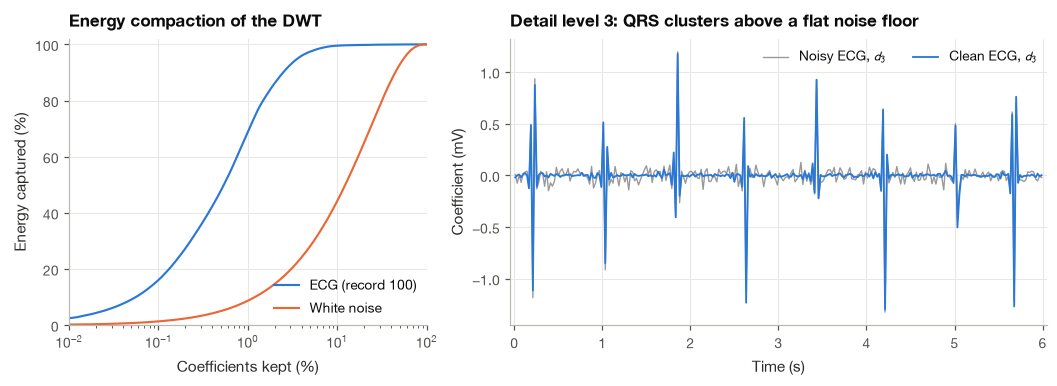

In [3]:
noisy_demo = ecg + 0.3 * noise                       # about 10 dB SNR
d3_clean = pywt.wavedec(ecg, wavelet, level=level, mode="periodization")[-3]
d3_noisy = pywt.wavedec(noisy_demo, wavelet, level=level, mode="periodization")[-3]
t_d3 = (np.arange(d3_clean.size) + 0.5) * 8 / fs     # each d3 coefficient covers 8 samples

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), gridspec_kw={"width_ratios": [1, 1.5]})
frac = np.arange(1, n_samples + 1) / n_samples * 100
axes[0].plot(frac, ce_ecg * 100, color=C[0], label="ECG (record 100)")
axes[0].plot(frac, ce_noise * 100, color=C[1], label="White noise")
axes[0].set(xscale="log", xlim=(0.01, 100), ylim=(0, 102), xlabel="Coefficients kept (%)",
            ylabel="Energy captured (%)", title="Energy compaction of the DWT")
axes[0].legend(loc="lower right")

keep = t_d3 < 6
axes[1].plot(t_d3[keep], d3_noisy[keep], color="0.6", lw=0.9, label="Noisy ECG, $d_3$")
axes[1].plot(t_d3[keep], d3_clean[keep], color=C[0], lw=1.2, label="Clean ECG, $d_3$")
axes[1].set(xlabel="Time (s)", ylabel="Coefficient (mV)", title="Detail level 3: QRS clusters above a flat noise floor")
axes[1].legend(loc="upper right", ncol=2)
plt.show()

The two facts derived above are easy to confirm. The cell below transforms pure white noise and prints the standard deviation of its coefficients at every level, then checks Parseval's relation on the ECG.

In [4]:
sigma = 0.05                                          # mV
v = sigma * rng.standard_normal(n_samples)
cv = pywt.wavedec(v, wavelet, level=level, mode="periodization")
names = [f"a{level}"] + [f"d{j}" for j in range(level, 0, -1)]
print("std of white-noise coefficients per band (true sigma = 0.050 mV):")
print("  " + "  ".join(f"{nm}: {c.std():.4f}" for nm, c in zip(names, cv)))
print(f"Parseval check: ||x||^2 = {np.sum(ecg**2):.4f},  ||Wx||^2 = {np.sum(w_ecg**2):.4f}")

std of white-noise coefficients per band (true sigma = 0.050 mV):
  a5: 0.0496  d5: 0.0464  d4: 0.0528  d3: 0.0499  d2: 0.0510  d1: 0.0500
Parseval check: ||x||^2 = 469.6160,  ||Wx||^2 = 469.6160


Every band has the same noise standard deviation, $0.05$ mV, to within sampling error. I use the `"periodization"` extension mode throughout this section because it makes the transform exactly orthonormal with exactly $N$ coefficients; other modes add a few boundary coefficients (Section 14.1.8) and the argument above holds only approximately.

(sec-14-2-2)=
## 14.2.2 Hard and Soft Thresholding

The oracle keeps a coefficient when $|\theta_i|$ is large. We only see $w_i$, so the natural imitation is to keep a coefficient when $|w_i|$ exceeds a threshold $\lambda$. There are two standard ways to do this. **Hard thresholding** is "keep or kill":

(eq-14-12)=
\begin{equation*}
\eta_H(w; \lambda) = \begin{cases} w, & |w| > \lambda, \\ 0, & |w| \le \lambda. \end{cases} \tag{14.12}
\end{equation*}

**Soft thresholding** kills the small coefficients as well, but also pulls every surviving coefficient toward zero by $\lambda$:

(eq-14-13)=
\begin{equation*}
\eta_S(w; \lambda) = \operatorname{sgn}(w)\,\max\big(|w| - \lambda,\ 0\big) = \begin{cases} w - \lambda, & w > \lambda, \\ 0, & |w| \le \lambda, \\ w + \lambda, & w < -\lambda. \end{cases} \tag{14.13}
\end{equation*}

The hard rule is discontinuous at $\pm\lambda$: a coefficient just below the threshold is set to zero, one just above it is kept at full size. Small changes in the data can therefore flip coefficients in and out, which produces visible blips in the reconstruction. The soft rule is continuous, but it is biased: a large coefficient that certainly belongs to the signal is still reduced by $\lambda$. For the ECG that bias falls on the largest coefficients of all, those of the QRS complex, and we will see it as a loss of R-wave amplitude.

### Where the two rules come from

Both rules are exact solutions of small optimization problems, which explains their shape. For soft thresholding, consider estimating one coefficient by minimizing a squared error plus a penalty on its magnitude,

(eq-14-14)=
\begin{equation*}
\eta_S(w;\lambda) = \arg\min_{\theta}\; f(\theta), \qquad f(\theta) = \tfrac12 (w - \theta)^2 + \lambda|\theta| . \tag{14.14}
\end{equation*}

The penalty $\lambda|\theta|$ favors small estimates, and its kink at zero is what produces exact zeros. We find the minimizer by cases.

**Case $\theta > 0$.** Here $|\theta| = \theta$ and $f$ is a smooth parabola, $f'(\theta) = \theta - w + \lambda$. Setting the derivative to zero gives $\theta = w - \lambda$. This candidate lies in the region $\theta > 0$ only if $w > \lambda$.

**Case $\theta < 0$.** Now $|\theta| = -\theta$, $f'(\theta) = \theta - w - \lambda$, and the stationary point $\theta = w + \lambda$ is negative only if $w < -\lambda$.

**Case $\theta = 0$.** If $|w| \le \lambda$, neither candidate exists. Then $f'(\theta) = \theta - w + \lambda > 0$ for every $\theta > 0$ (since $\lambda - w \ge 0$), so $f$ increases to the right of zero, and by the same argument it decreases to the left. The minimum is at $\theta = 0$.

Putting the three cases together gives exactly equation [(14.13)](#eq-14-13). Hard thresholding solves the same kind of problem with a penalty that counts nonzero coefficients instead of their size, $\tfrac12(w-\theta)^2 + \tfrac{\lambda^2}{2}\,\mathbb{1}[\theta \ne 0]$: if we keep the coefficient, the best value is $\theta = w$ and the cost is $\lambda^2/2$; if we kill it, the cost is $w^2/2$. Keeping wins exactly when $|w| > \lambda$, which is equation [(14.12)](#eq-14-12).

We implement both rules in NumPy, check them against PyWavelets, and confirm the soft rule by brute-force minimization of $f(\theta)$ on a fine grid.

In [5]:
def hard_threshold(w, lam):
    """Keep coefficients with |w| > lam and set the rest to zero, equation (24.12)."""
    return np.where(np.abs(w) > lam, w, 0.0)


def soft_threshold(w, lam):
    """Shrink every coefficient toward zero by lam, equation (24.13)."""
    return np.sign(w) * np.maximum(np.abs(w) - lam, 0.0)


w_test = rng.normal(0, 2, 10_000)
lam = 1.0
print("hard matches pywt:", np.allclose(hard_threshold(w_test, lam), pywt.threshold(w_test, lam, mode="hard")))
print("soft matches pywt:", np.allclose(soft_threshold(w_test, lam), pywt.threshold(w_test, lam, mode="soft")))

theta_grid = np.linspace(-6, 6, 120_001)
for w0 in (-3.2, -0.7, 0.4, 2.5):
    f = 0.5 * (w0 - theta_grid) ** 2 + lam * np.abs(theta_grid)
    print(f"w = {w0:+.1f}: grid minimizer {theta_grid[np.argmin(f)]:+.4f}, "
          f"soft threshold {soft_threshold(w0, lam):+.4f}")

hard matches pywt: True
soft matches pywt: True
w = -3.2: grid minimizer -2.2000, soft threshold -2.2000
w = -0.7: grid minimizer +0.0000, soft threshold -0.0000
w = +0.4: grid minimizer +0.0000, soft threshold +0.0000
w = +2.5: grid minimizer +1.5000, soft threshold +1.5000


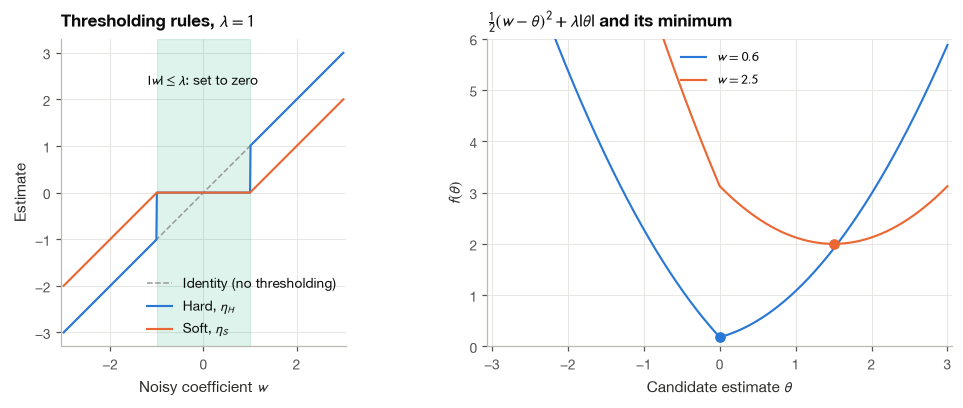

In [6]:
w_axis = np.linspace(-3, 3, 601)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
ax = axes[0]
ax.plot(w_axis, w_axis, "--", color="0.6", lw=1, label="Identity (no thresholding)")
ax.plot(w_axis, hard_threshold(w_axis, lam), color=C[0], label=r"Hard, $\eta_H$")
ax.plot(w_axis, soft_threshold(w_axis, lam), color=C[1], label=r"Soft, $\eta_S$")
ax.axvspan(-lam, lam, color=C[2], alpha=0.15)
ax.text(0, 2.3, r"$|w| \leq \lambda$: set to zero", ha="center", fontsize=9)
ax.set(xlabel="Noisy coefficient $w$", ylabel="Estimate", title=r"Thresholding rules, $\lambda = 1$")
ax.legend(loc="lower right")
ax.set_aspect("equal")

ax = axes[1]
for k, w0 in enumerate((0.6, 2.5)):
    f = 0.5 * (w0 - w_axis) ** 2 + lam * np.abs(w_axis)
    ax.plot(w_axis, f, color=C[k], label=f"$w = {w0}$")
    th = soft_threshold(w0, lam)
    ax.plot(th, 0.5 * (w0 - th) ** 2 + lam * abs(th), "o", color=C[k], ms=6)
ax.set(xlabel=r"Candidate estimate $\theta$", ylabel=r"$f(\theta)$",
       title=r"$\frac{1}{2}(w-\theta)^2 + \lambda|\theta|$ and its minimum", ylim=(0, 6))
ax.legend(loc="upper center")
plt.show()

In the right panel, the cost for $w = 0.6$ has its minimum at the kink, $\theta = 0$, while for $w = 2.5$ it is minimized at $\theta = 1.5 = w - \lambda$.

(sec-14-2-3)=
## 14.2.3 The Universal Threshold

How large should $\lambda$ be? Think about the coefficients where the signal is truly zero. There, $w_i = z_i$ is pure noise, and we want the threshold to kill it with high probability. If the threshold is too low, a handful of noise coefficients survive and reappear in the output as small isolated wavelets, which look like spurious notches on the ECG. So we need a threshold that is larger than the *maximum* of many independent Gaussian variables, not just larger than a typical one.

Donoho and Johnstone showed that the right size is

(eq-14-15)=
\begin{equation*}
\lambda_U = \sigma\sqrt{2\ln N}, \tag{14.15}
\end{equation*}

the **universal threshold** {cite:p}`donoho1994`. It grows with the number of coefficients, but very slowly: for $N = 16384$ it is $4.4\sigma$, and for a million samples it is still only $5.3\sigma$. Here is a sketch of why it works, in three steps. Write $\phi(u) = e^{-u^2/2}/\sqrt{2\pi}$ for the standard normal density.

**Step 1: a tail bound for one Gaussian.** For a standard normal $Z$ and $t > 0$, on the integration range $u \ge t$ we have $u/t \ge 1$, so

$$
P(Z > t) = \int_t^\infty \phi(u)\,du \;\le\; \int_t^\infty \frac{u}{t}\,\phi(u)\,du = \frac{1}{t}\Big[-\phi(u)\Big]_t^\infty = \frac{\phi(t)}{t}.
$$

The integral is easy because $\phi'(u) = -u\,\phi(u)$. By symmetry, $P(|Z| > t) \le 2\phi(t)/t$.

**Step 2: a union bound for the maximum.** The maximum of $N$ variables exceeds $t$ only if at least one of them does, and the probability of a union is at most the sum of the probabilities:

$$
P\Big(\max_{i} |z_i| > \sigma t\Big) \le N\, P(|Z| > t) \le \frac{2N\,\phi(t)}{t} = \frac{2N}{t\sqrt{2\pi}}\,e^{-t^2/2}.
$$

**Step 3: choose $t$ to cancel the factor $N$.** With $t = \sqrt{2\ln N}$ we get $e^{-t^2/2} = e^{-\ln N} = 1/N$, and the bound becomes

(eq-14-16)=
\begin{equation*}
P\Big(\max_{i} |z_i| > \sigma\sqrt{2\ln N}\Big) \le \frac{2}{\sqrt{2\pi}\,\sqrt{2\ln N}} = \frac{1}{\sqrt{\pi \ln N}} \;\longrightarrow\; 0 \quad (N \to \infty). \tag{14.16}
\end{equation*}

So with high probability every pure-noise coefficient falls below $\lambda_U$ and is set to zero, and the reconstruction is at least as smooth as the true signal. Donoho and Johnstone went further and proved that soft thresholding at $\lambda_U$ has an expected error within a factor of about $2\ln N + 1$ of the oracle error of Section 14.2.1, uniformly over all signals, and that no other estimator can improve that factor by more than a constant {cite:p}`donoho1994`. The price of not knowing where the signal is turns out to be only logarithmic.

Equation [(14.16)](#eq-14-16) is only an upper bound, so it is worth seeing how close it comes. We can simulate the maximum directly and compare it with $\sqrt{2\ln N}$.

    N  sqrt(2 ln N)  mean max|z|  P(max > threshold)  bound (24.16)
   16          2.35         2.08                0.24           0.34
  128          3.12         2.84                0.19           0.26
 1024          3.72         3.44                0.18           0.21
 8192          4.25         4.00                0.19           0.19
65536          4.71         4.47                0.17           0.17


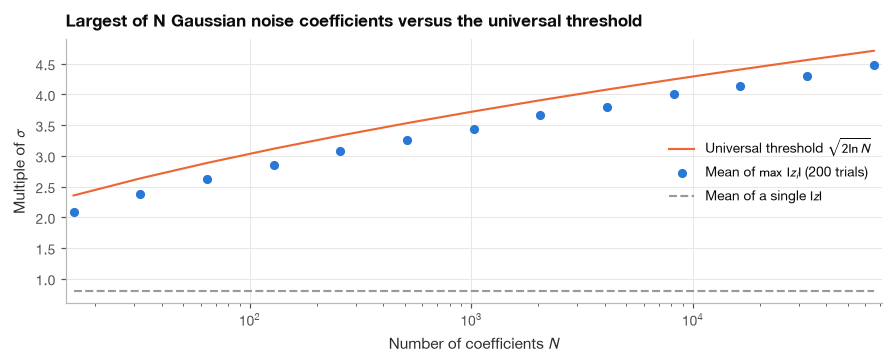

In [7]:
n_values = 2 ** np.arange(4, 17)
n_trials = 200
mean_max, p_exceed = [], []
for n in n_values:
    z = rng.standard_normal((n_trials, n))
    m = np.abs(z).max(axis=1)
    mean_max.append(m.mean())
    p_exceed.append(np.mean(m > np.sqrt(2 * np.log(n))))

table = pd.DataFrame({"N": n_values, "sqrt(2 ln N)": np.sqrt(2 * np.log(n_values)),
                      "mean max|z|": mean_max, "P(max > threshold)": p_exceed,
                      "bound (24.16)": 1 / np.sqrt(np.pi * np.log(n_values))})
print(table.iloc[::3].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(n_values, np.sqrt(2 * np.log(n_values)), color=C[1], label=r"Universal threshold $\sqrt{2\ln N}$")
ax.plot(n_values, mean_max, "o", color=C[0], ms=5, label=r"Mean of $\max\,|z_i|$ (200 trials)")
ax.plot(n_values, np.sqrt(2 / np.pi) * np.ones_like(n_values, dtype=float), "--", color="0.6",
        label=r"Mean of a single $|z|$")
ax.set(xscale="log", xlabel="Number of coefficients $N$", ylabel="Multiple of $\\sigma$",
       title="Largest of N Gaussian noise coefficients versus the universal threshold")
ax.legend(loc="center right")
plt.show()

The maximum of the noise grows like $\sqrt{2\ln N}$ and stays a quarter of a standard deviation below it. The probability that at least one noise coefficient leaks through is about 17 to 24% in the table, and for large $N$ the bound (14.16) is surprisingly tight. A leak is not a disaster: the leaking coefficient is barely larger than the threshold, so after soft thresholding it contributes almost nothing, and even after hard thresholding it is a single small wavelet.

The universal threshold has a well-known drawback that matters for physiological signals. It was designed to remove *all* noise, and it does so by being conservative. Real coefficients that are smaller than about $4\sigma$ (in the ECG, much of the P wave and the low-amplitude parts of the T wave) are removed together with the noise. We will measure this in Section 14.2.5.

(sec-14-2-4)=
## 14.2.4 Estimating the Noise Level and Adapting the Threshold

### The MAD estimate of $\sigma$

Equation [(14.15)](#eq-14-15) requires the noise standard deviation $\sigma$, which we never know in practice. The finest detail level $d_1$ is the natural place to estimate it. At 360 Hz it covers 90 to 180 Hz, where the ECG has almost no energy, so $d_1$ is mostly noise. Mostly, but not entirely: the steepest parts of each QRS complex leave a few large coefficients there. The sample standard deviation is sensitive to such outliers, so we use the **median absolute deviation** instead,

(eq-14-17)=
\begin{equation*}
\hat\sigma = \frac{\operatorname{median}\big(|d_1[k]|\big)}{0.6745}. \tag{14.17}
\end{equation*}

The constant 0.6745 comes from the Gaussian distribution. If $z \sim \mathcal{N}(0, \sigma^2)$, the median $m$ of $|z|$ is the value that $|z|$ falls below half of the time:

$$
\begin{aligned}
\tfrac12 = P(|z| \le m) &= P(-m \le z \le m) \\
&= \Phi(m/\sigma) - \Phi(-m/\sigma) \\
&= 2\,\Phi(m/\sigma) - 1,
\end{aligned}
$$

where $\Phi$ is the standard normal cumulative distribution function and the last line uses its symmetry, $\Phi(-u) = 1 - \Phi(u)$. Solving gives $\Phi(m/\sigma) = 3/4$, so $m = \Phi^{-1}(0.75)\,\sigma = 0.6745\,\sigma$. Dividing the observed median by 0.6745 therefore gives an unbiased-in-the-limit estimate of $\sigma$. Because the median ignores the size of the largest values, up to half of the coefficients could be QRS outliers without ruining the estimate. That is the property that makes it suitable here.

In [8]:
from scipy.stats import norm

def mad_sigma(d):
    """Robust noise standard deviation from detail coefficients, equation (24.17)."""
    return np.median(np.abs(d)) / 0.6745

print(f"Phi^-1(0.75) = {norm.ppf(0.75):.4f}")

sigma_true = 0.3 * ecg.std()                          # noise used in noisy_demo above
cd = pywt.wavedec(noisy_demo, wavelet, level=level, mode="periodization")
print(f"true sigma               : {sigma_true:.4f} mV")
for j in (1, 2, 3):
    d = cd[-j]
    print(f"level d{j}: MAD estimate {mad_sigma(d):.4f} mV,  sample std {d.std():.4f} mV")

Phi^-1(0.75) = 0.6745
true sigma               : 0.0508 mV
level d1: MAD estimate 0.0502 mV,  sample std 0.0507 mV
level d2: MAD estimate 0.0571 mV,  sample std 0.0663 mV
level d3: MAD estimate 0.0650 mV,  sample std 0.2130 mV


At level 1 both estimates are within about 1% of the true value, because this record has so little energy above 90 Hz. One level down the QRS complex starts to contribute, and at $d_3$, which holds the bulk of the QRS energy, the MAD estimate is 28% too large while the sample standard deviation is four times too large. The median resists the QRS outliers far better, but no estimator can separate noise from signal in a level that is dominated by signal. This is why the noise is estimated from the finest level only.

### BayesShrink: one threshold per level

A single universal threshold treats all levels alike. The ECG does not: $d_3$ and $d_4$ are full of QRS energy, while $d_1$ is nearly empty. Chang, Yu and Vetterli proposed choosing a separate threshold for each level from a Bayesian argument {cite:p}`chang2000`. They model the clean coefficients in a level as draws from a peaked, heavy-tailed prior (a generalized Gaussian, which includes the Laplacian), with standard deviation $\sigma_x$, and look for the soft threshold that minimizes the expected squared error under that prior. The exact minimizer has no closed form, but they showed numerically that

(eq-14-18)=
\begin{equation*}
\lambda_B = \frac{\sigma^2}{\sigma_x} \tag{14.18}
\end{equation*}

is within a few percent of optimal over the range of priors that occur in practice. The formula behaves sensibly at both extremes. When the signal dominates a level ($\sigma_x \gg \sigma$), the threshold becomes small and the level is left almost untouched. When the level holds almost no signal ($\sigma_x \to 0$), the threshold grows without bound and the whole level is removed.

We need $\sigma_x$ for each level. Because signal and noise are independent with zero mean, their variances add, so the variance of the observed coefficients $w$ in a level is $\sigma_w^2 = \sigma_x^2 + \sigma^2$. That gives the estimate

$$
\hat\sigma_x = \sqrt{\max\big(\hat\sigma_w^2 - \hat\sigma^2,\ 0\big)}, \qquad \hat\sigma_w^2 = \frac{1}{N_j}\sum_k w_j[k]^2,
$$

where $N_j$ is the number of coefficients at level $j$. The $\max$ guards against a negative variance estimate; when it happens we set $\lambda_B$ to the largest coefficient magnitude in that level, which removes the level entirely.

In [9]:
def bayes_threshold(d, sigma):
    """BayesShrink threshold sigma^2 / sigma_x for one detail level, equation (24.18)."""
    sigma_x = np.sqrt(max(np.mean(d**2) - sigma**2, 0.0))
    return np.abs(d).max() if sigma_x == 0 else sigma**2 / sigma_x


sigma_hat = mad_sigma(cd[-1])
lam_u = sigma_hat * np.sqrt(2 * np.log(n_samples))
print(f"universal threshold: {lam_u:.3f} mV at every level")
for j in range(1, level + 1):
    d = cd[-j]
    print(f"d{j}: BayesShrink threshold {bayes_threshold(d, sigma_hat):6.3f} mV  "
          f"({bayes_threshold(d, sigma_hat) / lam_u:4.2f} x universal)")

universal threshold: 0.221 mV at every level
d1: BayesShrink threshold  0.348 mV  (1.58 x universal)
d2: BayesShrink threshold  0.058 mV  (0.26 x universal)
d3: BayesShrink threshold  0.012 mV  (0.05 x universal)
d4: BayesShrink threshold  0.006 mV  (0.03 x universal)
d5: BayesShrink threshold  0.005 mV  (0.02 x universal)


The level-dependent thresholds follow the ECG's energy distribution: a threshold larger than the universal one in $d_1$, where there is little to keep, about one noise standard deviation in $d_2$, and thresholds twenty to fifty times smaller than the universal one in $d_3$ to $d_5$, where the QRS complex dominates and the rule leaves the coefficients almost untouched.

(sec-14-2-5)=
## 14.2.5 Denoising a Real ECG Step by Step

We now put the pieces together on record 100. The noise in this first experiment is white and Gaussian, the situation for which the theory was built; Section 14.2.6 turns to real muscle noise.

### Step 1: Add noise at a known signal-to-noise ratio

To compare methods we need a controlled experiment, so we scale a noise record $v[n]$ to reach a chosen input SNR. With the definitions of Section 3.4, the gain $g$ that gives $\text{SNR}_{\text{in}}$ decibels satisfies $10\log_{10}\!\big(\sum x^2 / \sum (g v)^2\big) = \text{SNR}_{\text{in}}$, so $g = \sqrt{\sum x^2 / (10^{\text{SNR}_{\text{in}}/10}\sum v^2)}$. The quality of an estimate $\hat x$ is measured by the output SNR and by the **percentage root-mean-square difference** that is common in the ECG compression and denoising literature,

(eq-14-19)=
\begin{equation*}
\text{SNR}_{\text{out}} = 10\log_{10}\frac{\sum_n x[n]^2}{\sum_n \big(\hat x[n] - x[n]\big)^2}, \qquad
\text{PRD} = 100\,\sqrt{\frac{\sum_n \big(\hat x[n] - x[n]\big)^2}{\sum_n x[n]^2}}\ \%. \tag{14.19}
\end{equation*}

The two carry the same information, since $\text{SNR}_{\text{out}} = -20\log_{10}(\text{PRD}/100)$, but PRD is the figure most ECG papers report.

In [10]:
def add_noise(x, v, snr_db):
    """Scale noise v so that x + g v has the requested SNR in dB."""
    g = np.sqrt(np.sum(x**2) / (np.sum(v**2) * 10 ** (snr_db / 10)))
    return x + g * v


def snr_db(x, x_hat):
    """Output SNR in dB, equation (24.19)."""
    return 10 * np.log10(np.sum(x**2) / np.sum((x_hat - x) ** 2))


def prd(x, x_hat):
    """Percentage root-mean-square difference, equation (24.19)."""
    return 100 * np.sqrt(np.sum((x_hat - x) ** 2) / np.sum(x**2))


white = rng.standard_normal(n_samples)
noisy = add_noise(ecg, white, 10.0)
print(f"input SNR: {snr_db(ecg, noisy):.2f} dB,  input PRD: {prd(ecg, noisy):.1f} %")

input SNR: 10.00 dB,  input PRD: 31.6 %


### Step 2: Decompose and estimate the noise level

I use the `sym4` wavelet (a near-symmetric Daubechies wavelet with four vanishing moments) and five levels. At 360 Hz, five levels leave an approximation $a_5$ covering 0 to 5.6 Hz, which holds the P and T waves' slowest components and is never thresholded; the details $d_1$ to $d_5$ span 5.6 to 180 Hz (Section 14.1.6).

In [11]:
coeffs = pywt.wavedec(noisy, wavelet, level=level, mode="periodization")
sigma_hat = mad_sigma(coeffs[-1])
sigma_used = np.sqrt(np.sum(ecg**2) / (np.sum(white**2) * 10)) * white.std()
print(f"estimated sigma: {sigma_hat:.4f} mV   (actual noise sigma {sigma_used:.4f} mV)")
print(f"universal threshold: {sigma_hat * np.sqrt(2 * np.log(n_samples)):.4f} mV")

estimated sigma: 0.0549 mV   (actual noise sigma 0.0535 mV)
universal threshold: 0.2420 mV


### Step 3: Threshold the details and reconstruct

The complete procedure fits in one function. It thresholds every detail level, either with the universal threshold and a hard or soft rule, or with BayesShrink, and leaves the approximation alone. The option `sigma_per_level` estimates $\sigma$ separately at each level with equation [(14.17)](#eq-14-17); we will need it for colored noise.

In [12]:
def wavelet_denoise(y, wavelet="sym4", level=5, rule="bayes", sigma_per_level=False):
    """Wavelet shrinkage: DWT, threshold the details, inverse DWT."""
    coeffs = pywt.wavedec(y, wavelet, level=level, mode="periodization")
    sigma = mad_sigma(coeffs[-1])
    out = [coeffs[0]]
    for d in coeffs[1:]:
        s = mad_sigma(d) if sigma_per_level else sigma
        if rule == "bayes":
            out.append(soft_threshold(d, bayes_threshold(d, s)))
        else:
            lam = s * np.sqrt(2 * np.log(y.size))
            out.append(hard_threshold(d, lam) if rule == "hard" else soft_threshold(d, lam))
    return pywt.waverec(out, wavelet, mode="periodization")


estimates = {rule: wavelet_denoise(noisy, rule=rule) for rule in ("hard", "soft", "bayes")}

### Step 4: Compare the outputs

           rule  SNR out (dB)  SNR gain (dB)  PRD (%)
universal, hard         14.27           4.27    19.34
universal, soft         10.71           0.71    29.15
    BayesShrink         15.73           5.73    16.36


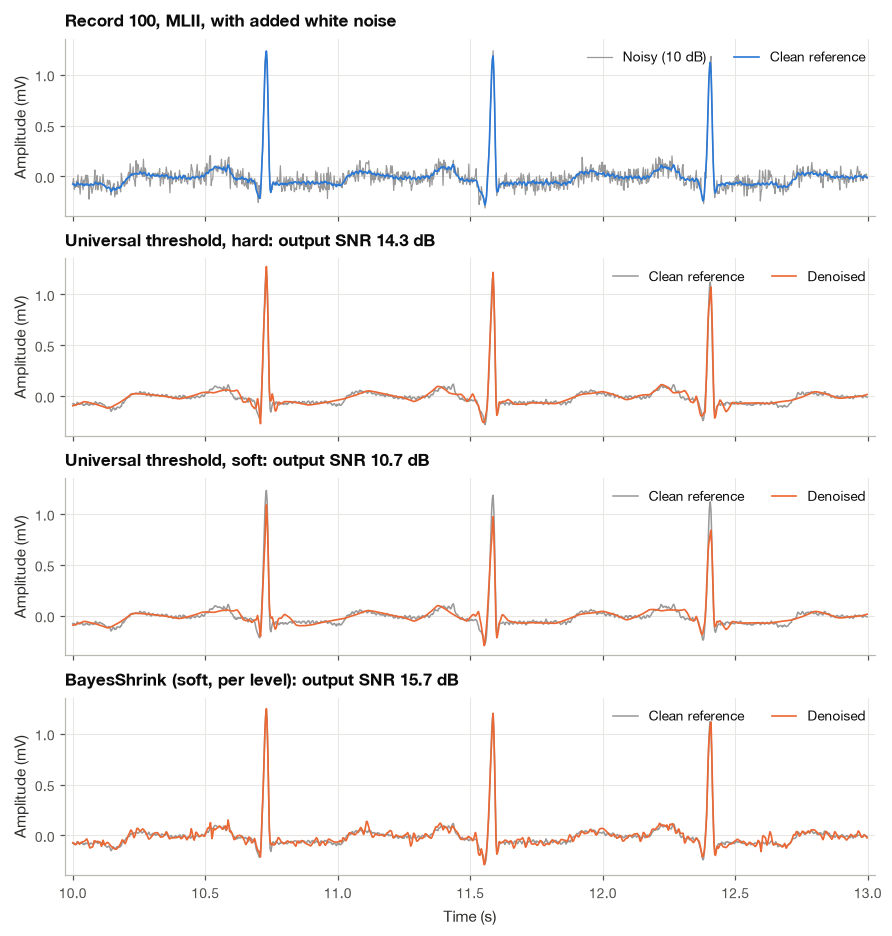

In [13]:
rows = []
for rule, x_hat in estimates.items():
    rows.append({"rule": {"hard": "universal, hard", "soft": "universal, soft", "bayes": "BayesShrink"}[rule],
                 "SNR out (dB)": snr_db(ecg, x_hat), "SNR gain (dB)": snr_db(ecg, x_hat) - 10.0,
                 "PRD (%)": prd(ecg, x_hat)})
print(pd.DataFrame(rows).to_string(index=False))

win = (t >= 10) & (t < 13)
fig, axes = plt.subplots(4, 1, figsize=(8, 8.4), sharex=True, sharey=True)
axes[0].plot(t[win], noisy[win], color="0.6", lw=0.8, label="Noisy (10 dB)")
axes[0].plot(t[win], ecg[win], color=C[0], lw=1.1, label="Clean reference")
axes[0].set_title("Record 100, MLII, with added white noise")
titles = {"hard": "Universal threshold, hard", "soft": "Universal threshold, soft", "bayes": "BayesShrink (soft, per level)"}
for ax, rule in zip(axes[1:], ("hard", "soft", "bayes")):
    ax.plot(t[win], ecg[win], color="0.6", lw=1.0, label="Clean reference")
    ax.plot(t[win], estimates[rule][win], color=C[1], lw=1.1, label="Denoised")
    ax.set_title(f"{titles[rule]}: output SNR {snr_db(ecg, estimates[rule]):.1f} dB")
for ax in axes:
    ax.set_ylabel("Amplitude (mV)")
    ax.legend(loc="upper right", ncol=2)
axes[-1].set_xlabel("Time (s)")
plt.show()

The three outputs differ in the way the theory predicts. Hard thresholding keeps the QRS complexes at full height but leaves small oscillations where a noise coefficient leaked through or where a signal coefficient near the threshold was cut. Soft thresholding gives a smooth baseline but visibly shortens the R waves and rounds off the P waves, the shrinkage bias of Section 14.2.2. BayesShrink is the best of the three by output SNR, yet its baseline is the least smooth: it removes almost all of $d_1$ and the noise-sized coefficients of $d_2$, but it leaves the noise in $d_3$ to $d_5$ nearly intact. It wins because it never damages the signal, and in this record the signal energy in those levels far outweighs the noise that rides along. SNR rewards fidelity to the waveform, not a clean-looking baseline, and I find it useful to keep both criteria in mind.

### Step 5: Check the choice of wavelet and level

The number of levels and the wavelet are design choices, and I prefer to make them by measurement rather than by habit. The next cell averages the output SNR over five noise realizations at 10 dB input SNR for five wavelets and five decomposition depths.

In [14]:
wavelets = ["haar", "db4", "sym4", "sym8", "coif3"]
levels = [3, 4, 5, 6, 7]
noise_bank = [rng.standard_normal(n_samples) for _ in range(5)]
noisy_bank = [add_noise(ecg, v, 10.0) for v in noise_bank]

results = {}
for rule in ("hard", "bayes"):
    grid = np.zeros((len(wavelets), len(levels)))
    for i, wv in enumerate(wavelets):
        for k, lv in enumerate(levels):
            grid[i, k] = np.mean([snr_db(ecg, wavelet_denoise(y, wv, lv, rule)) for y in noisy_bank])
    results[rule] = pd.DataFrame(grid, index=wavelets, columns=[f"L={lv}" for lv in levels])

for rule, name in (("hard", "Universal threshold, hard"), ("bayes", "BayesShrink")):
    print(f"{name}: mean output SNR (dB), input 10 dB")
    print(results[rule].to_string(), "\n")

Universal threshold, hard: mean output SNR (dB), input 10 dB
         L=3    L=4    L=5    L=6    L=7
haar   13.79  13.67  13.11  12.85  12.64
db4    15.52  15.54  14.63  14.11  13.89
sym4   15.39  15.33  14.39  13.82  13.71
sym8   15.51  15.45  14.50  14.02  13.80
coif3  15.34  15.05  14.26  13.72  13.53 

BayesShrink: mean output SNR (dB), input 10 dB
         L=3    L=4    L=5    L=6    L=7
haar   13.83  13.93  13.97  13.97  13.98
db4    15.53  15.66  15.68  15.69  15.69
sym4   15.47  15.60  15.63  15.64  15.64
sym8   15.65  15.77  15.80  15.80  15.80
coif3  15.55  15.68  15.71  15.71  15.72 



Two patterns stand out. The Haar wavelet is clearly worse than the smoother wavelets: its blocky basis functions do not match the rounded shape of the QRS complex, so the ECG is less sparse in the Haar basis and more of it falls below the threshold. Among the smooth wavelets the differences are a few tenths of a decibel, so the exact choice matters less than avoiding Haar. Depth behaves differently for the two rules. With a single universal threshold, more levels means applying a large threshold to the low-frequency details where the P and T waves live, and the output SNR drops steadily. BayesShrink adapts its threshold to each level and is essentially indifferent to depth beyond four levels. This insensitivity is the practical reason I recommend a level-adaptive rule as the default for the ECG.

(sec-14-2-6)=
## 14.2.6 Performance over Noise Levels and on Real Muscle Noise

### White noise at several SNRs

A single operating point can mislead, so we sweep the input SNR from $-5$ to 20 dB and include a fourth-order zero-phase Butterworth low-pass filter at 40 Hz as the conventional baseline (Section 18.3).

          Universal, hard  Universal, soft  BayesShrink  Butterworth 40 Hz
-5.0 dB              2.83             1.40         4.77               1.90
+0.0 dB              7.69             4.21         8.22               6.74
+5.0 dB             11.49             7.61        11.74              11.24
+10.0 dB            14.39            10.81        15.63              14.96
+15.0 dB            17.93            13.93        19.37              17.39
+20.0 dB            21.19            16.97        22.94              18.57


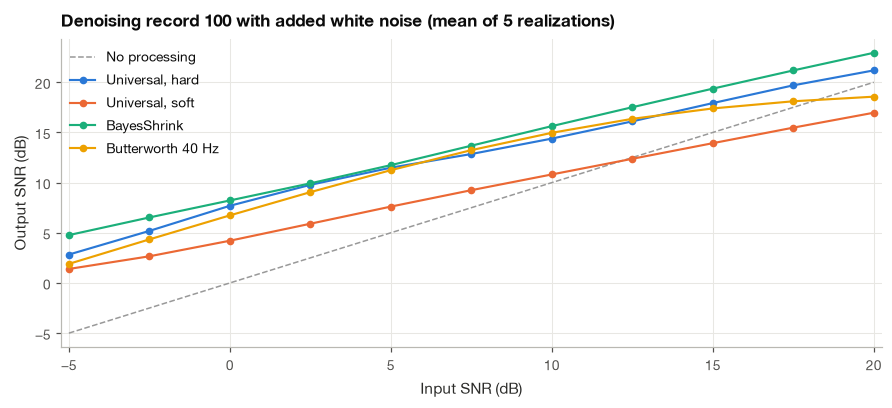

In [15]:
sos_lp40 = signal.butter(4, 40, fs=fs, output="sos")
methods = {
    "Universal, hard": lambda y: wavelet_denoise(y, rule="hard"),
    "Universal, soft": lambda y: wavelet_denoise(y, rule="soft"),
    "BayesShrink": lambda y: wavelet_denoise(y, rule="bayes"),
    "Butterworth 40 Hz": lambda y: signal.sosfiltfilt(sos_lp40, y),
}
snr_in = np.arange(-5, 21, 2.5)
sweep = {name: [np.mean([snr_db(ecg, f(add_noise(ecg, v, s))) for v in noise_bank]) for s in snr_in]
         for name, f in methods.items()}
print(pd.DataFrame(sweep, index=[f"{s:+.1f} dB" for s in snr_in]).iloc[::2].round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(snr_in, snr_in, "--", color="0.6", lw=1, label="No processing")
for k, (name, vals) in enumerate(sweep.items()):
    ax.plot(snr_in, vals, "-o", color=C[k], ms=4, label=name)
ax.set(xlabel="Input SNR (dB)", ylabel="Output SNR (dB)",
       title="Denoising record 100 with added white noise (mean of 5 realizations)")
ax.legend(loc="upper left")
plt.show()

BayesShrink is the best method at every input SNR, with a gain that falls from almost 10 dB at $-5$ dB input to about 3 dB at 20 dB input. The Butterworth low-pass filter is a strong competitor on white noise between 5 and 10 dB, where it trails BayesShrink by only half a decibel, and this deserves an honest comment. White noise at 360 Hz spreads its power evenly from 0 to 180 Hz, while the ECG of record 100 has almost no energy above 40 Hz, so a 40 Hz cutoff removes about three quarters of the noise power at almost no cost to the signal. The wavelet methods win by a modest margin in this middle range, and the margin comes from something a fixed filter cannot do: they also remove in-band noise during the isoelectric segments, where no large coefficients exist. At the two ends of the range the filter falls behind for opposite reasons. At low SNR the noise left below 40 Hz dominates its output, and at high SNR its output is limited by the signal it removes: the curve flattens near 18.6 dB because the filter cuts the high-frequency part of the QRS whatever the noise level. Soft thresholding with the universal threshold is the weakest method at every noise level because its bias removes signal energy along with the noise.

### Real muscle noise

The MIT-BIH Noise Stress Test Database contains real muscle artifact (`ma`) recorded from electrodes placed where the ECG is negligible {cite:p}`moody1984`. We filter it with the same 0.5 Hz high-pass filter as the ECG and add it at 5 dB SNR. The key question is whether muscle noise is white. We can answer it directly with the MAD estimator, applied at every level separately to the added noise alone (first table). The second table then compares the SNR gains of the denoising methods for white noise and for muscle noise at the same 5 dB input SNR, with $\sigma$ estimated either once from $d_1$ or separately at every level.

In [16]:
ma = wfdb.rdrecord("../data/nstdb/ma", sampto=n_samples, channels=[0]).p_signal[:, 0]
ma = signal.sosfiltfilt(sos_hp, ma - ma.mean())
noisy_ma = add_noise(ecg, ma, 5.0)
noisy_wn = add_noise(ecg, white, 5.0)

c_ma = pywt.wavedec(noisy_ma - ecg, wavelet, level=level, mode="periodization")
c_wn = pywt.wavedec(noisy_wn - ecg, wavelet, level=level, mode="periodization")
bands = [f"d{j} ({fs / 2 ** (j + 1):.0f}-{fs / 2 ** j:.0f} Hz)" for j in range(1, level + 1)]
print(pd.DataFrame({"white noise sigma (mV)": [mad_sigma(c_wn[-j]) for j in range(1, level + 1)],
                    "muscle noise sigma (mV)": [mad_sigma(c_ma[-j]) for j in range(1, level + 1)]},
                   index=bands).to_string(float_format=lambda v: f"{v:.4f}"))

rows = []
for name, y in (("white noise", noisy_wn), ("muscle noise (nstdb ma)", noisy_ma)):
    for label, x_hat in (("Universal hard, sigma from d1", wavelet_denoise(y, rule="hard")),
                         ("Universal hard, sigma per level", wavelet_denoise(y, rule="hard", sigma_per_level=True)),
                         ("BayesShrink, sigma from d1", wavelet_denoise(y, rule="bayes")),
                         ("BayesShrink, sigma per level", wavelet_denoise(y, rule="bayes", sigma_per_level=True)),
                         ("Butterworth 40 Hz", signal.sosfiltfilt(sos_lp40, y))):
        rows.append({"noise": name, "method": label, "SNR gain (dB)": snr_db(ecg, x_hat) - 5.0})
print(pd.DataFrame(rows).pivot(index="method", columns="noise", values="SNR gain (dB)").round(2).to_string())

                white noise sigma (mV)  muscle noise sigma (mV)
d1 (90-180 Hz)                  0.0969                   0.0063
d2 (45-90 Hz)                   0.0930                   0.0257
d3 (22-45 Hz)                   0.0960                   0.0681
d4 (11-22 Hz)                   0.0972                   0.0786
d5 (6-11 Hz)                    0.0867                   0.0550
noise                            muscle noise (nstdb ma)  white noise
method                                                               
BayesShrink, sigma from d1                          0.03         6.77
BayesShrink, sigma per level                        0.72         7.07
Butterworth 40 Hz                                   0.65         6.26
Universal hard, sigma from d1                       0.03         6.51
Universal hard, sigma per level                     0.89         4.58


In the first table, the white noise has the same standard deviation at every level, as derived in Section 14.2.1. The muscle noise does not: it is weakest in $d_1$ and more than ten times stronger in $d_3$ and $d_4$, the 11 to 45 Hz range, which is exactly where the QRS complex lives. (The rest of its power lies below 5.6 Hz, in the approximation, where no detail threshold can touch it.) Two consequences follow. A threshold computed from $d_1$ underestimates the noise in the levels that matter, so the noise in $d_2$ and $d_3$ survives. And even a correct level-dependent threshold {cite:p}`johnstone1997` cannot separate noise from QRS energy that occupies the same coefficients.

In the second table, every method gains between 4.6 and 7.1 dB on white noise. On real muscle noise the best gain is below one decibel, whatever the method. Estimating $\sigma$ per level helps, raising the gain from almost nothing to 0.7 to 0.9 dB, but it cannot do more. I find this result more instructive than any success story. Wavelet shrinkage relies on the signal being sparse *and* the noise being spread thinly over all coefficients. Muscle noise violates the second assumption, because it is itself a train of sharp, spike-like motor unit potentials that the wavelet basis represents compactly, in the same bands as the QRS. When signal and noise overlap in time, in frequency and in shape, no single-channel transform will separate them. The remedies are to use more information: averaging over many beats ([Section 10.1](../ch16_noise_removal/01_signal_averaging.ipynb)), a reference channel for adaptive cancellation (Section 16.3), or several leads and source separation (Chapter 25).

(sec-14-2-7)=
## 14.2.7 What Denoising Does to the QRS Complex

Output SNR summarizes the error over the whole record, but a cardiologist looks at specific features. The R-wave amplitude is used in criteria for left ventricular hypertrophy, and the sharpness of the QRS onset matters for interval measurements. Both are damaged by smoothing. We measure the R-peak amplitude of each estimate at the 56 annotated beats of the segment, within $\pm 5$ samples of the annotation, and compare it with the clean reference. I add a second low-pass filter at 25 Hz, a cutoff that is sometimes used in monitoring mode on bedside monitors.

In [17]:
def r_amplitude(x, peaks, half_width=5):
    """Maximum of x within +/- half_width samples of each annotated R peak."""
    return np.array([x[p - half_width:p + half_width + 1].max() for p in peaks])

sos_lp25 = signal.butter(4, 25, fs=fs, output="sos")
candidates = {
    "Butterworth 25 Hz": signal.sosfiltfilt(sos_lp25, noisy),
    "Butterworth 40 Hz": signal.sosfiltfilt(sos_lp40, noisy),
    "Universal, soft": estimates["soft"],
    "Universal, hard": estimates["hard"],
    "BayesShrink": estimates["bayes"],
}
r_ref = r_amplitude(ecg, r_peaks)
rows = [{"method": name, "SNR out (dB)": snr_db(ecg, x_hat),
         "mean R change (%)": 100 * np.mean((r_amplitude(x_hat, r_peaks) - r_ref) / r_ref)}
        for name, x_hat in candidates.items()]
print(f"{r_peaks.size} beats, mean clean R amplitude {r_ref.mean():.3f} mV")
print(pd.DataFrame(rows).to_string(index=False))

56 beats, mean clean R amplitude 1.226 mV
           method  SNR out (dB)  mean R change (%)
Butterworth 25 Hz          9.98             -24.99
Butterworth 40 Hz         14.97              -5.93
  Universal, soft         10.71             -17.19
  Universal, hard         14.27               1.92
      BayesShrink         15.73              -0.18


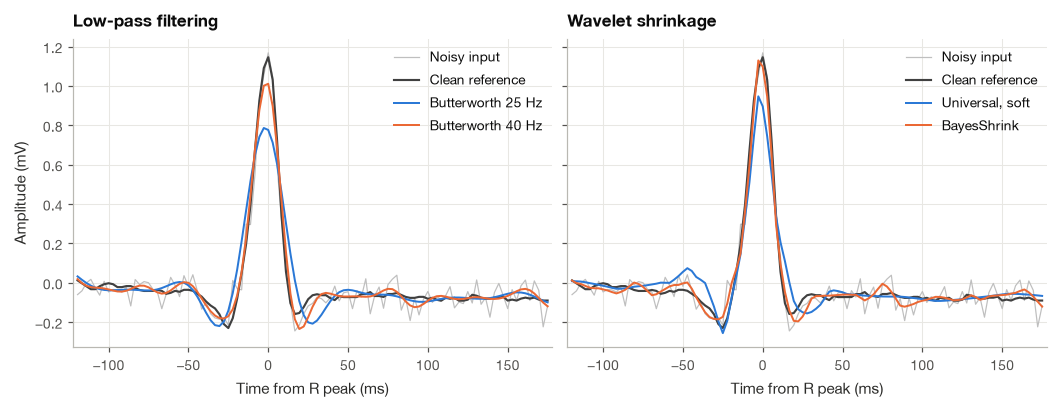

In [18]:
beat = r_peaks[12]
seg = slice(beat - int(0.12 * fs), beat + int(0.18 * fs))
tt = (np.arange(seg.start, seg.stop) - beat) / fs * 1000
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
for ax, names, title in ((axes[0], ["Butterworth 25 Hz", "Butterworth 40 Hz"], "Low-pass filtering"),
                         (axes[1], ["Universal, soft", "BayesShrink"], "Wavelet shrinkage")):
    ax.plot(tt, noisy[seg], color="0.75", lw=0.8, label="Noisy input")
    ax.plot(tt, ecg[seg], color="0.25", lw=1.4, label="Clean reference")
    for k, name in enumerate(names):
        ax.plot(tt, candidates[name][seg], color=C[k], lw=1.3, label=name)
    ax.set(xlabel="Time from R peak (ms)", title=title)
    ax.legend(loc="upper right")
axes[0].set_ylabel("Amplitude (mV)")
plt.show()

The 25 Hz low-pass filter and the soft universal rule both remove a large fraction of the R-wave amplitude; the soft rule does so because the largest coefficients are exactly the ones its bias reduces by a full $\lambda$. The 40 Hz filter loses about 6%, while hard thresholding and BayesShrink preserve the R-wave amplitude to within 2% (the small positive bias of the hard rule comes from residual noise riding on the peak), because the QRS coefficients are either kept intact or shrunk by a threshold that is small compared with their size. If a downstream algorithm measures amplitudes, as many hypertrophy and ischemia criteria do, this difference matters more than a decibel of SNR.

(sec-14-2-8)=
## 14.2.8 Translation-Invariant Denoising with the Stationary Wavelet Transform

The DWT is not shift-invariant. Shifting the input by one sample changes the coefficients substantially, because the downsampling grid stays where it is while the signal moves (we met this in Section 14.1). For denoising this has a visible consequence. Whether a given QRS complex is represented by one large coefficient or split between two medium ones depends on where it falls relative to the grid, and when a split coefficient is cut by the threshold, the reconstruction shows small oscillations near the sharp edges, sometimes called pseudo-Gibbs artifacts.

Coifman and Donoho proposed a direct fix called **cycle spinning** {cite:p}`coifman1995`: shift the signal, denoise, shift back, and average over all shifts,

(eq-14-20)=
\begin{equation*}
\hat{x}_{\text{TI}}[n] = \frac{1}{S}\sum_{s=0}^{S-1} \Big(\mathcal{D}\big(y[\,\cdot + s\,]\big)\Big)[n - s], \tag{14.20}
\end{equation*}

where $\mathcal{D}$ denotes DWT denoising with circular shifts. For a $J$-level transform only $S = 2^J$ shifts give different results, because a shift by $2^J$ samples moves every level's grid by a whole number of coefficients. The artifacts of different shifts appear in different places and average out, while the signal, which is the same in every shifted version, is preserved.

Computing $2^J$ transforms looks expensive, but the average can be obtained in one pass with the **stationary wavelet transform** (SWT, also called the undecimated or à trous transform). The SWT applies the same filters as the DWT but does not downsample; instead, the filters at level $j$ are upsampled by inserting $2^{j-1} - 1$ zeros between their taps. Every level then has $N$ coefficients, which together hold the DWT coefficients for all $2^J$ shifts at once. With the default normalization in PyWavelets, the filters at each level have unit energy, so white noise of variance $\sigma^2$ still has variance $\sigma^2$ in every SWT band and the same thresholds apply. The inverse SWT averages the reconstructions of the interleaved subsequences, which is exactly the average in equation [(14.20)](#eq-14-20). We can verify that claim numerically by comparing the SWT result with explicit cycle spinning over 32 shifts with a fixed threshold.

In [19]:
def dwt_hard_fixed(y, lam, wavelet="sym4", level=5):
    """DWT denoising with a fixed hard threshold (periodic boundaries)."""
    c = pywt.wavedec(y, wavelet, level=level, mode="periodization")
    return pywt.waverec([c[0]] + [hard_threshold(d, lam) for d in c[1:]], wavelet, mode="periodization")


def swt_denoise(y, wavelet="sym4", level=5, rule="hard", lam=None):
    """Translation-invariant shrinkage with the stationary wavelet transform."""
    c = pywt.swt(y, wavelet, level=level, trim_approx=True)
    sigma = mad_sigma(c[-1])
    out = [c[0]]
    for d in c[1:]:
        if rule == "bayes":
            out.append(soft_threshold(d, bayes_threshold(d, sigma)))
        else:
            thr = sigma * np.sqrt(2 * np.log(y.size)) if lam is None else lam
            out.append(hard_threshold(d, thr) if rule == "hard" else soft_threshold(d, thr))
    return pywt.iswt(out, wavelet)


lam_fixed = mad_sigma(coeffs[-1]) * np.sqrt(2 * np.log(n_samples))
spun = np.mean([np.roll(dwt_hard_fixed(np.roll(noisy, s), lam_fixed), -s) for s in range(2**level)], axis=0)
swt_out = swt_denoise(noisy, rule="hard", lam=lam_fixed)
print(f"max |cycle spinning - SWT| = {np.max(np.abs(spun - swt_out)):.2e} mV")

max |cycle spinning - SWT| = 6.66e-16 mV


The two agree to machine precision. Now we compare the DWT and SWT versions of each rule on the same five noise realizations at 5 and 10 dB.

 input SNR (dB)            rule  DWT (dB)  SWT (dB)  improvement (dB)
            5.0 Universal, hard     11.49     14.77              3.28
            5.0 Universal, soft      7.61      8.79              1.17
            5.0     BayesShrink     11.74     12.65              0.91
           10.0 Universal, hard     14.39     17.62              3.23
           10.0 Universal, soft     10.81     12.47              1.65
           10.0     BayesShrink     15.63     16.34              0.71


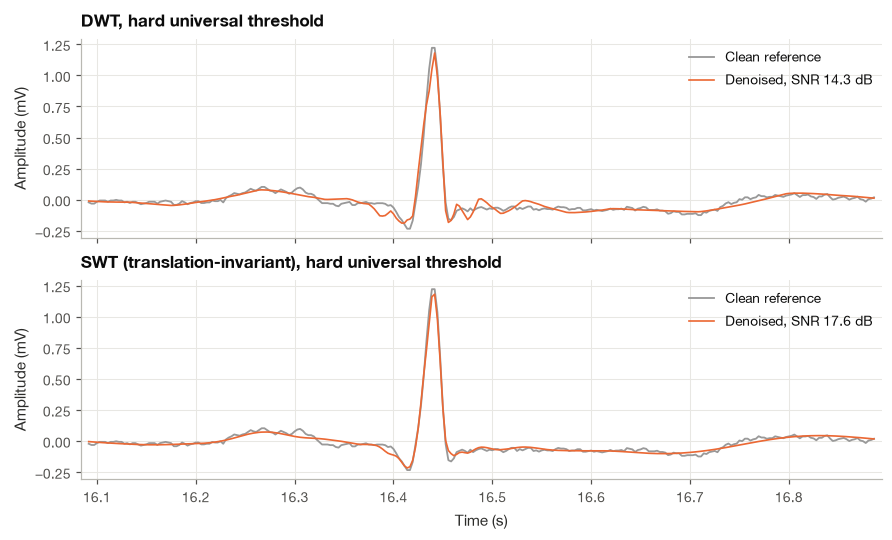

In [20]:
rows = []
for s in (5.0, 10.0):
    for rule, name in (("hard", "Universal, hard"), ("soft", "Universal, soft"), ("bayes", "BayesShrink")):
        dwt_snr = np.mean([snr_db(ecg, wavelet_denoise(add_noise(ecg, v, s), rule=rule)) for v in noise_bank])
        swt_snr = np.mean([snr_db(ecg, swt_denoise(add_noise(ecg, v, s), rule=rule)) for v in noise_bank])
        rows.append({"input SNR (dB)": s, "rule": name, "DWT (dB)": dwt_snr, "SWT (dB)": swt_snr,
                     "improvement (dB)": swt_snr - dwt_snr})
print(pd.DataFrame(rows).to_string(index=False))

dwt_hard = estimates["hard"]
swt_hard = swt_denoise(noisy, rule="hard")
seg = slice(r_peaks[20] - int(0.35 * fs), r_peaks[20] + int(0.45 * fs))
tt = t[seg]
fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True, sharey=True)
for ax, est, title in ((axes[0], dwt_hard, "DWT, hard universal threshold"),
                       (axes[1], swt_hard, "SWT (translation-invariant), hard universal threshold")):
    ax.plot(tt, ecg[seg], color="0.6", lw=1.2, label="Clean reference")
    ax.plot(tt, est[seg], color=C[1], lw=1.1, label=f"Denoised, SNR {snr_db(ecg, est):.1f} dB")
    ax.set(ylabel="Amplitude (mV)", title=title)
    ax.legend(loc="upper right")
axes[1].set_xlabel("Time (s)")
plt.show()

The improvement is largest for the hard rule, the one whose discontinuity causes the artifacts in the first place, and the SWT version of hard thresholding becomes the best estimator in this section. Averaging over shifts also softens the bias of the soft rule somewhat, because the shrinkage is spread over many overlapping basis functions. The cost is memory and time: the SWT stores $(J+1)N$ coefficients instead of $N$ and needs $O(N\log N)$ rather than $O(N)$ operations, which is irrelevant for offline analysis of a Holter record and still affordable on most wearable processors. The one practical constraint is that PyWavelets' SWT requires the length to be a multiple of $2^J$, which is why I chose $N = 2^{14}$; for other lengths we pad the signal (for example by reflection) and trim afterwards.

```{note}
Denoising is a means, not an end. If the next step is QRS detection, a band-pass filter tuned to the QRS spectrum is usually enough, and the Pan–Tompkins detector in Section 19.1 works on a heavily filtered signal that nobody would call a faithful ECG. Wavelet shrinkage earns its place when the morphology itself is the object of measurement: amplitudes, intervals, ST levels, or beat shapes fed to a classifier.
```

## Summary

Wavelet denoising rests on two properties of an orthonormal DWT: it keeps white noise white with the same variance in every coefficient, and it represents the ECG sparsely, with a small fraction of coefficients carrying almost all of its energy. Estimating each coefficient separately then becomes a scalar problem, and thresholding is its natural solution. Hard thresholding keeps or kills; soft thresholding also shrinks the survivors, which we derived as the minimizer of a squared error plus an absolute-value penalty. The universal threshold $\sigma\sqrt{2\ln N}$ follows from the size of the largest of $N$ Gaussian noise coefficients, and the noise level is estimated from the finest detail level with the median absolute deviation divided by 0.6745. BayesShrink replaces the single threshold with one per level, $\sigma^2/\sigma_x$, and was the best of the decimated methods on record 100, where it also preserved the R-wave amplitude, unlike the soft universal rule and a 25 Hz low-pass filter. The stationary wavelet transform averages the estimate over all circular shifts and removes the pseudo-Gibbs artifacts of the decimated transform. On real muscle noise, which is colored and overlaps the QRS in both frequency and shape, every single-channel method gained less than a decibel.

That last result points ahead. When noise cannot be separated from the signal within one channel, we need several channels and a model of how sources mix, which is the subject of principal and independent component analysis in Chapter 25. The thresholded wavelet coefficients will also return as compact features for heartbeat classification in Section 27.1.

## Exercises

1. Show that for $w$ observed in $\mathcal{N}(\theta, \sigma^2)$ noise, the expected squared error of the "kill" estimate $\hat\theta = 0$ is $\theta^2$ and that of the "keep" estimate $\hat\theta = w$ is $\sigma^2$. Use this to justify the oracle error $\sum_i \min(\theta_i^2, \sigma^2)$ of Section 14.2.1.
2. Repeat the derivation of equation [(14.14)](#eq-14-14) for the penalty $\lambda\theta^2$ instead of $\lambda|\theta|$. Show that the minimizer is $w/(1 + 2\lambda)$ and explain why this "ridge" rule never produces exact zeros. Which linear filter does it correspond to when applied with the same $\lambda$ to every coefficient?
3. Compute the MAD-based estimate of $\sigma$ for pure white noise of known variance, with $N = 64, 256, 1024$ and $4096$ coefficients, over 2000 trials each. Compare the spread of the MAD estimate with that of the sample standard deviation. How much efficiency does robustness cost when there are no outliers?
4. Replace the white noise in Section 14.2.5 by the electrode-motion artifact `em` from `nstdb`, at 5 dB SNR. Estimate the noise level per band as in Section 14.2.6 and explain, from the result, why wavelet shrinkage of the detail levels cannot remove it. Which part of the decomposition would you have to modify?
5. Implement SureShrink, which chooses each level's soft threshold by minimizing Stein's unbiased risk estimate $\text{SURE}(\lambda) = N_j\sigma^2 - 2\sigma^2\,\#\{k: |w_k| \le \lambda\} + \sum_k \min(w_k^2, \lambda^2)$ over $\lambda \in \{|w_k|\}$. Compare it with BayesShrink on record 100 at input SNRs from 0 to 20 dB.
6. Denoise records 105 (very noisy) and 119 (frequent ventricular beats) from `book/data/mitdb` with the SWT and BayesShrink, without adding noise. There is no clean reference, so design and justify an evaluation that does not need one, for example the beat-to-beat variability of median-aligned normal beats before and after denoising.

## Further Reading

The theory of wavelet shrinkage, including the universal threshold and its near-oracle property, is in {cite:t}`donoho1994`, and {cite:t}`donoho1995` shows that soft thresholding produces estimates at least as smooth as the true signal with high probability. {cite:t}`chang2000` derive BayesShrink, {cite:t}`johnstone1997` treat level-dependent thresholds for correlated noise, and {cite:t}`coifman1995` introduce cycle spinning. {cite:t}`mallat2009` covers all of these within a unified treatment of sparse representations, and {cite:t}`addison2005` surveys applications of wavelets to the ECG, including denoising.